## Trabajo Práctico N° 2: Prediccion de lluvia en Australia

#### Variable de salida (target): 'RainTomorrow'

In [1]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split

### EDA

#### Lectura y primera vista del dataset

In [2]:
df = pd.read_csv("weatherAUS_2026C2.csv")
df = df.reset_index(drop=True)

print(f"Cantidad de filas: {df.shape[0]}")
print(f"Cantidad de columnas: {df.shape[1]}")

Cantidad de filas: 145412
Cantidad de columnas: 25


In [3]:
display(df.head())

,Unnamed: 0,Date,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,...,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RainTomorrow,RainfallTomorrow
0,0,2008-12-01,Albury,13.6,22.5,0.6,NaN,NaN,W,45.0,...,23.8,1008.1,1007.2,8.0,NaN,16.8,20.8,No,No,0.0
1,1,2008-12-02,Albury,7.3,25.8,0.0,NaN,NaN,WNW,44.0,...,22.1,1011.1,1007.5,NaN,NaN,18.3,24.6,No,No,0.0
2,2,2008-12-03,Albury,13.2,26.2,0.0,NaN,NaN,WSW,46.0,...,31.5,1007.3,1009.4,NaN,2.0,21.2,23.4,No,No,0.0
3,3,2008-12-04,Albury,10.0,28.8,0.0,NaN,NaN,NE,23.0,...,18.5,1017.6,1012.4,NaN,NaN,17.4,26.3,No,No,1.0
4,4,2008-12-05,Albury,17.4,32.4,1.0,NaN,NaN,W,41.0,...,34.6,1010.9,1005.9,7.0,8.0,17.9,29.1,No,No,0.2


Se detectó una columna "Unnamed: 0" que repite los indices, se elimina para evitar problemas

In [4]:
df = df.drop(columns=["Unnamed: 0"], errors="ignore")
df = df.reset_index(drop=True)

display(df.head())

,Date,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,WindDir9am,...,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RainTomorrow,RainfallTomorrow
0,2008-12-01,Albury,13.6,22.5,0.6,NaN,NaN,W,45.0,W,...,23.8,1008.1,1007.2,8.0,NaN,16.8,20.8,No,No,0.0
1,2008-12-02,Albury,7.3,25.8,0.0,NaN,NaN,WNW,44.0,NNW,...,22.1,1011.1,1007.5,NaN,NaN,18.3,24.6,No,No,0.0
2,2008-12-03,Albury,13.2,26.2,0.0,NaN,NaN,WSW,46.0,W,...,31.5,1007.3,1009.4,NaN,2.0,21.2,23.4,No,No,0.0
3,2008-12-04,Albury,10.0,28.8,0.0,NaN,NaN,NE,23.0,SE,...,18.5,1017.6,1012.4,NaN,NaN,17.4,26.3,No,No,1.0
4,2008-12-05,Albury,17.4,32.4,1.0,NaN,NaN,W,41.0,ENE,...,34.6,1010.9,1005.9,7.0,8.0,17.9,29.1,No,No,0.2


#### Descripcion general

In [5]:
print("\nInformación general:")
df.info()


Información general:
<class 'pandas.DataFrame'>
RangeIndex: 145412 entries, 0 to 145411
Data columns (total 24 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Date              145412 non-null  str    
 1   Location          145412 non-null  str    
 2   MinTemp           143928 non-null  float64
 3   MaxTemp           144159 non-null  float64
 4   Rainfall          142152 non-null  float64
 5   Evaporation       82658 non-null   float64
 6   Sunshine          75616 non-null   float64
 7   WindGustDir       135096 non-null  str    
 8   WindGustSpeed     135159 non-null  float64
 9   WindDir9am        134850 non-null  str    
 10  WindDir3pm        141186 non-null  str    
 11  WindSpeed9am      143645 non-null  float64
 12  WindSpeed3pm      142351 non-null  float64
 13  Humidity9am       142759 non-null  float64
 14  Humidity3pm       140907 non-null  float64
 15  Pressure9am       130351 non-null  float64
 16  Pressure3

#### Variables Generales

Date: Fecha de la observación. Location: La ubicación o ciudad en Australia.

Variables de Temperatura, en °C

MinTemp: Temperatura mínima del día. MaxTemp: Temperatura máxima del día. Temp9am: Temperatura registrada a las 9 de la mañana. Temp3pm: Temperatura registrada a las 3 de la tarde.

Variables de Precipitación y Humedad

Rainfall: La cantidad de lluvia registrada ese día, en mm. Evaporation: Evaporación de agua de "Clase A" en las 24 horas hasta las 9 am, en milímetros (mm). Sunshine: El número de horas de sol brillante durante el día. Humidity9am: La humedad relativa a las 9 de la mañana, como un porcentaje. Humidity3pm: La humedad relativa a las 3 de la tarde, como un porcentaje. RainToday: Indica si hubo precipitación (más de 1 mm) en ese día, o no.

Variables de Viento

WindGustDir: La dirección de la ráfaga de viento más fuerte del día (ej. N, S, SW). WindGustSpeed: La velocidad de la ráfaga de viento más fuerte del día, en km/h. WindDir9am: La dirección del viento a las 9 de la mañana. WindDir3pm: La dirección del viento a las 3 de la tarde. WindSpeed9am: La velocidad promedio del viento, a las 9 de la mañana, en km/h. WindSpeed3pm: La velocidad promedio del viento a las 3 de la tarde, en km/h.

Variables Atmosféricas

Pressure9am: La presión atmosférica a nivel del mar a las 9 de la mañana, medida en hectopascales (hPa). Pressure3pm: La presión atmosférica a las 3 de la tarde, en hPa. Cloud9am: La fracción del cielo cubierta por nubes a las 9 de la mañana. Se mide en "oktas", una escala de 0 (cielo completamente despejado) a 8 (cielo completamente cubierto). Cloud3pm: La fracción del cielo cubierta por nubes a las 3 de la tarde.

Variable Objetivo

RainTomorrow: Variable categórica ('Yes'/'No') que responde a la pregunta: "¿Llovió al día siguiente?".

RainfallTomorrow es una caracteristica que mide en mm la cantidad de lluvia que va a caer mañana, es decir, es informacion del futuro que se relaciona con el target, ya que si es mayor a 1 (umbral del dataset) sabemos que RainTomorrow es 'Si'. Se elimin para evitar fuga de datos.

In [6]:
df = df.drop(columns=["RainfallTomorrow"])

Trabajamos con una serie temporal, por lo que vamos a pasar la fecha a formato Date y reordenalo cronologicamente

In [7]:
df["Date"] = pd.to_datetime(df["Date"])
df = df.sort_values("Date").reset_index(drop=True)

print(f"Fecha mínima: {df['Date'].min().date()}")
print(f"Fecha máxima: {df['Date'].max().date()}")

Fecha mínima: 2007-11-01
Fecha máxima: 2017-06-24


#### Análisis de nulos y duplicados

In [8]:
print("Valores faltantes por columna:")

nulos = pd.DataFrame({
    "Cantidad": df.isnull().sum(),
    "Porcentaje": round(df.isnull().mean()*100,2)
})

display(nulos.sort_values("Porcentaje", ascending=False))

print(f"\nCantidad de registros totalmente nulos:")
print(len(df[df.isna().all(axis=1)])) 

print("\nFilas sin target (RainTomorrow):", df['RainTomorrow'].isnull().sum()) 

print(f"\nFilas duplicadas: {df.duplicated().sum()}")

Valores faltantes por columna:


,Cantidad,Porcentaje
Sunshine,69796,48.00
Evaporation,62754,43.16
Cloud3pm,59336,40.81
Cloud9am,55870,38.42
Pressure9am,15061,10.36
Pressure3pm,15024,10.33
WindDir9am,10562,7.26
WindGustDir,10316,7.09
WindGustSpeed,10253,7.05
Humidity3pm,4505,3.10



Cantidad de registros totalmente nulos:
0

Filas sin target (RainTomorrow): 3259

Filas duplicadas: 0


Se detectaron 3259 sin la variable target. Para el presente análisis se descartarán estas filas debido a que no se puede evaluar ni entrenar supervisado sin etiqueta

In [9]:
df = df.dropna(subset=['RainTomorrow'])
df = df.dropna(how='all')
print(f"Dataset después de eliminar filas con target nulo: {df.shape[0]:,} Registros con {df.shape[1]} características")

print(f"\nValores faltantes por columna despues de eliminar filas con target nulo:")

nulos2 = pd.DataFrame({
    "Cantidad": df.isnull().sum(),
    "Porcentaje": round(df.isnull().mean()*100,2)
})

display(nulos2.sort_values("Porcentaje", ascending=False))

Dataset después de eliminar filas con target nulo: 142,153 Registros con 23 características

Valores faltantes por columna despues de eliminar filas con target nulo:


,Cantidad,Porcentaje
Sunshine,67785,47.68
Evaporation,60812,42.78
Cloud3pm,57076,40.15
Cloud9am,53641,37.73
Pressure9am,14010,9.86
Pressure3pm,13977,9.83
WindDir9am,10009,7.04
WindGustDir,9328,6.56
WindGustSpeed,9268,6.52
WindDir3pm,3776,2.66


#### Conteo de nulos por fila

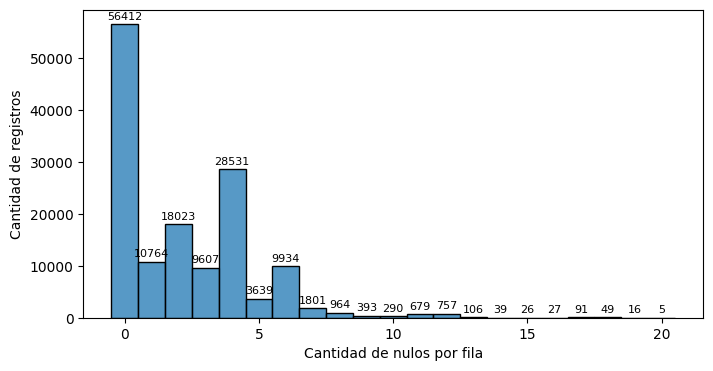

In [10]:
nulos_fila = df.isnull().sum(axis=1)

plt.figure(figsize=(8,4))
ax = sns.histplot(nulos_fila, discrete=True)

ax.bar_label(ax.containers[0], fontsize=8, padding=2)

plt.xlabel("Cantidad de nulos por fila")
plt.ylabel("Cantidad de registros")
plt.show()

#### Promedio de nulos por cuidad

In [11]:
(df.drop(columns="Location")
   .isnull()
   .groupby(df["Location"])
   .mean()
   .mul(100)
   .round(2))

,Date,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,WindDir9am,WindDir3pm,...,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RainTomorrow
Location,,,,,,,,,,,,,,,,,,,,,
Adelaide,0.0,0.06,0.06,2.27,46.63,45.05,0.74,0.74,8.38,0.49,...,0.16,0.16,0.26,0.23,100.00,100.00,0.16,0.13,2.27,0.0
Albany,0.0,1.96,1.06,0.66,9.25,16.75,100.00,100.00,8.09,25.41,...,1.53,23.18,0.83,0.80,1.16,23.02,1.19,23.05,0.66,0.0
Albury,0.0,0.20,0.03,0.66,100.00,100.00,0.33,0.33,17.18,1.36,...,0.13,0.13,0.00,0.13,57.44,53.02,0.13,0.13,0.66,0.0
AliceSprings,0.0,0.03,0.03,0.20,6.96,16.86,1.65,1.65,7.59,0.13,...,0.10,0.16,0.03,0.10,10.95,11.81,0.00,0.07,0.20,0.0
BadgerysCreek,0.0,0.41,0.10,1.74,100.00,100.00,0.55,0.55,13.46,2.05,...,0.99,1.06,4.89,5.06,100.00,100.00,0.55,0.68,1.74,0.0
Ballarat,0.0,0.03,0.03,0.36,100.00,100.00,0.79,0.79,3.01,0.53,...,0.69,0.20,0.79,0.79,17.97,34.39,0.40,0.17,0.36,0.0
Bendigo,0.0,0.03,0.03,0.13,60.93,100.00,1.19,1.15,8.01,1.38,...,0.16,0.03,0.46,0.30,31.78,25.29,0.07,0.03,0.13,0.0
Brisbane,0.0,0.19,0.13,0.92,0.60,1.52,0.47,0.47,2.18,0.85,...,0.06,0.28,0.00,0.06,0.03,0.06,0.06,0.28,0.92,0.0
Cairns,0.0,0.03,0.00,0.80,11.38,14.23,0.60,0.57,1.41,0.13,...,0.00,0.00,0.00,0.00,6.19,6.90,0.00,0.00,0.80,0.0


#### Posible patron en la presencia de nulos

In [12]:
columnas = ["Evaporation", "Sunshine", "Cloud3pm", "Cloud9am"]

nulos_simultaneos_por_fila = df[columnas].isna().all(axis=1)

resumen_ciudades = nulos_simultaneos_por_fila.groupby(df["Location"]).agg(todas_las_filas_nulas="all",cantidad_filas="size") #True si todas las filas de la ciudad tienen nulos simultáneos en el bloque

ciudades_con_nulos_simultaneos = (resumen_ciudades.loc[resumen_ciudades["todas_las_filas_nulas"], "cantidad_filas"].rename_axis("Ciudad").reset_index(name="Cantidad de filas"))

total_ciudades = df["Location"].nunique()
ciudades_con_nulos = ciudades_con_nulos_simultaneos["Ciudad"].nunique()
porcentaje = ciudades_con_nulos / total_ciudades * 100

print(f"Ciudades con nulos simultaneos: {ciudades_con_nulos} de {total_ciudades} ({porcentaje:.2f}%)")
display(ciudades_con_nulos_simultaneos)

Ciudades con nulos simultaneos: 10 de 49 (20.41%)


,Ciudad,Cantidad de filas
0,BadgerysCreek,2927
1,GoldCoast,2979
2,MountGinini,2906
3,Nhil,1568
4,NorahHead,2928
5,Penrith,2963
6,SalmonGums,2954
7,Tuggeranong,2997
8,Walpole,2818
9,Witchcliffe,2951


Probamos tambien con 2 de las 4 columnas

In [13]:
columnas = ["Evaporation", "Sunshine"]

nulos_simultaneos_por_fila = df[columnas].isna().all(axis=1)

resumen_ciudades = nulos_simultaneos_por_fila.groupby(df["Location"]).agg(todas_las_filas_nulas="all",cantidad_filas="size") #True si todas las filas de la ciudad tienen nulos simultáneos en el bloque

ciudades_con_nulos_simultaneos = (resumen_ciudades.loc[resumen_ciudades["todas_las_filas_nulas"], "cantidad_filas"].rename_axis("Ciudad").reset_index(name="Cantidad de filas"))

total_ciudades = df["Location"].nunique()
ciudades_con_nulos = ciudades_con_nulos_simultaneos["Ciudad"].nunique()
porcentaje = ciudades_con_nulos / total_ciudades * 100

print(f"Ciudades con nulos simultaneos: {ciudades_con_nulos} de {total_ciudades} ({porcentaje:.2f}%)")
display(ciudades_con_nulos_simultaneos)

Ciudades con nulos simultaneos: 15 de 49 (30.61%)


,Ciudad,Cantidad de filas
0,Albury,3010
1,BadgerysCreek,2927
2,Ballarat,3027
3,GoldCoast,2979
4,MountGinini,2906
5,Newcastle,2955
6,Nhil,1568
7,NorahHead,2928
8,Penrith,2963
9,SalmonGums,2954


En el histograma original habia un pico marcado en 4 y otro mas pequeño en 2, lo que nos permitió detectar un patron. Al analizar los faltantes por cuidad, nos dimos cuenta que habia varias cuidades en las que se repetian pares de caracteristicas totalmente nulas: "Evaporation" - "Sunshine" y "Cloud3pm" -"Cloud9am". En muchos casos estos dos pares nulos aparecen al mismo tiempo. El 20.41% de las cuidades presenta las 4 caracteristicas juntas al mismo tiempo, mientras que el par "Evaporation" - "Sunshine" aparece totalmente nulo en el 30.61% de ellas. Esto sugiere que dichos atributos no fueron medidos por cuestiones meteorológicas, no se trata de valores faltantes aleatorios sino estructurales.

Volvemos a calcular el histograma pero dejando solo los nulos reales, eliminando los que vengas de una columna 100% nula

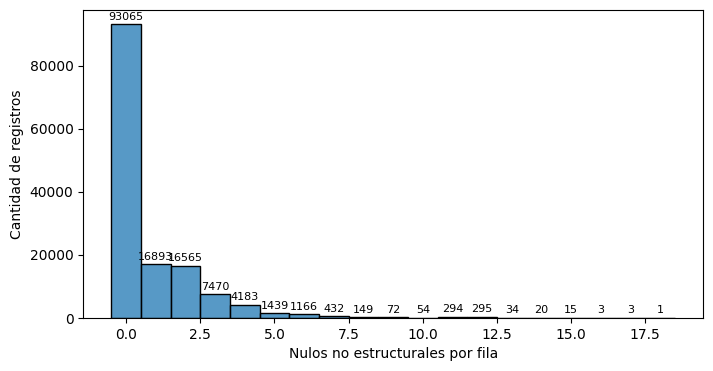

In [14]:
caracteristicas = [c for c in df.columns if c not in ['Date', 'Location', 'RainTomorrow', 'RainfallTomorrow']] 
nulos_totales = df[caracteristicas].isnull().sum(axis=1) 

# True si la columna es 100% nula en la ciudad de esa fila
mascara = df.groupby('Location')[caracteristicas].transform(lambda s: s.isnull().all())

# Guardo los nulos que son estructurales (los que son nulos en todas las filas de la ciudad)
nulos_estructurales = mascara.sum(axis=1)

nulos_reales = nulos_totales - nulos_estructurales

plt.figure(figsize=(8,4))
ax = sns.histplot(nulos_reales, discrete=True)

ax.bar_label(ax.containers[0],
             labels=[int(v) if v > 0 else '' for v in ax.containers[0].datavalues],
             fontsize=8, padding=2)

plt.xlabel("Nulos no estructurales por fila")
plt.ylabel("Cantidad de registros")
plt.show()

#### Eliminacion de filas con nulos: 8 o mas nulos

In [15]:
nulos_por_fila = nulos_reales
umbral = 8

filas_eliminar = nulos_por_fila >= umbral

cant_eliminar = filas_eliminar.sum()
cant_total = len(df)
porcentaje = cant_eliminar / cant_total * 100

print(f"Umbral seleccionado: {umbral} o mas valores nulos")
print(f"Filas a eliminar: {cant_eliminar:,}")
print(f"Total de filas: {cant_total:,}")
print(f"Porcentaje eliminado: {porcentaje:.2f}%")

Umbral seleccionado: 8 o mas valores nulos
Filas a eliminar: 940
Total de filas: 142,153
Porcentaje eliminado: 0.66%


In [16]:
df = df.loc[~filas_eliminar].copy()
df = df.reset_index(drop=True)

print(f"Filas restantes: {len(df):,}")
print(f"Nuevo tamaño del dataset: {df.shape}")

Filas restantes: 141,213
Nuevo tamaño del dataset: (141213, 23)


Se eliminaron los registros con ocho o más valores faltantes. Este criterio descartó el 0,66% del conjunto de datos, los cuales son registros casi vacíos, en los que imputar sería inventar la mayor parte de la fila.

#### Incorporacion de informacion geografica auxiliar

Durante el analisis de valores faltantes observamos que algunas variables presentan faltantes estructurales concentrados en determinadas estaciones meteorologicas, lo que indica que ciertas mediciones nunca fuero registradas en estas ubicaciones. Para poder realizar la imputacion con observaciones climaticamente similares, vamos a incorporar de forma temporal el estado australiano al que pertenece cada Location.
No vamos a obtener la informacion del dataset, sino de informacion geografica conocida. Para no depender de fuentes externas, se construyó manualmente un diccionario que relaciona cada una de las 49 estaciones meteorológicas con su estado correspondiente. La variable 'State' será utilizada únicamente durante el proceso de imputación y posteriormente será eliminada.

In [17]:
state_map = {
    "Albury": "NSW",
    "BadgerysCreek": "NSW",
    "Cobar": "NSW",
    "CoffsHarbour": "NSW",
    "Moree": "NSW",
    "Newcastle": "NSW",
    "NorahHead": "NSW",
    "NorfolkIsland": "External",
    "Penrith": "NSW",
    "Richmond": "NSW",
    "Sydney": "NSW",
    "SydneyAirport": "NSW",
    "WaggaWagga": "NSW",
    "Williamtown": "NSW",
    "Wollongong": "NSW",

    "Canberra": "ACT",
    "Tuggeranong": "ACT",
    "MountGinini": "ACT",

    "Ballarat": "VIC",
    "Bendigo": "VIC",
    "Sale": "VIC",
    "Melbourne": "VIC",
    "MelbourneAirport": "VIC",
    "Mildura": "VIC",
    "Nhil": "VIC",
    "Portland": "VIC",
    "Watsonia": "VIC",
    "Dartmoor": "VIC",

    "Brisbane": "QLD",
    "Cairns": "QLD",
    "GoldCoast": "QLD",
    "Townsville": "QLD",
    "MountIsa": "QLD",

    "AliceSprings": "NT",
    "Darwin": "NT",
    "Katherine": "NT",
    "Uluru": "NT",

    "Adelaide": "SA",
    "MountGambier": "SA",
    "Nuriootpa": "SA",
    "Woomera": "SA",

    "Perth": "WA",
    "PerthAirport": "WA",
    "Albany": "WA",
    "Witchcliffe": "WA",
    "SalmonGums": "WA",
    "Walpole": "WA",
    "PearceRAAF": "WA",

    "Hobart": "TAS",
    "Launceston": "TAS",
}

Incorporamos la columna de estado al dataset

In [18]:
df["State"] = df["Location"].map(state_map)

display(df["State"].value_counts(dropna=False).rename_axis("Estado").reset_index(name="Cantidad de filas"))


,Estado,Cantidad de filas
0,NSW,40878
1,VIC,28001
2,WA,20599
3,QLD,12158
4,SA,12100
5,NT,9268
6,ACT,9040
7,TAS,6209
8,External,2960


#### Diseño de caracteristicas temporales

Para no afectar la naturaleza ciclica de los meses y las estaciones, vamos a transformar el mes con la funcion seno y coseno, obteniendo dos variables continuas 'Mes_sin' y 'Mes_cos', que representan la proximidad entre todos los meses del año

In [19]:
df["Mes"] = df["Date"].dt.month

df["Mes_sin"] = np.sin(2*np.pi*df["Mes"]/12)
df["Mes_cos"] = np.cos(2*np.pi*df["Mes"]/12)

meses = (
    df[["Mes", "Mes_sin", "Mes_cos"]]
    .drop_duplicates()
    .sort_values("Mes")
)

display(meses)

,Mes,Mes_sin,Mes_cos
61,1,5.000000e-01,8.660254e-01
92,2,8.660254e-01,5.000000e-01
150,3,1.000000e+00,6.123234e-17
212,4,8.660254e-01,-5.000000e-01
272,5,5.000000e-01,-8.660254e-01
334,6,1.224647e-16,-1.000000e+00
394,7,-5.000000e-01,-8.660254e-01
636,8,-8.660254e-01,-5.000000e-01
878,9,-1.000000e+00,-1.836970e-16
1116,10,-8.660254e-01,5.000000e-01


Eliminamos la columna Mes ya que no la necesitamos para la representacion ciclica

In [20]:
df.drop(columns="Mes", inplace=True)

#### Wind direction


Las variables correspondientes a la dirección del viento representan una magnitud angular, por lo que presentan el mismo problema de continuidad que los meses del año. Para preservar esta naturaleza cíclica, cada dirección se transforma mediante las funciones seno y coseno de su ángulo asociado.

In [21]:
df['WindGustDir'].unique()

<ArrowStringArray>
[ 'NW', 'ENE', 'SSE',  'SE',   'E',   'S',   'N', 'WNW', 'ESE',  'NE', 'NNE',
 'NNW',  'SW',   'W', 'WSW',   nan, 'SSW']
Length: 17, dtype: str

In [22]:

wind_map = {
    "N": 0,
    "NNE": 22.5,
    "NE": 45,
    "ENE": 67.5,
    "E": 90,
    "ESE": 112.5,
    "SE": 135,
    "SSE": 157.5,
    "S": 180,
    "SSW": 202.5,
    "SW": 225,
    "WSW": 247.5,
    "W": 270,
    "WNW": 292.5,
    "NW": 315,
    "NNW": 337.5,
}

wind_cols = ["WindGustDir", "WindDir9am", "WindDir3pm"]

for col in wind_cols:

    angulos = df[col].map(wind_map)

    df[f"{col}_sin"] = np.sin(np.deg2rad(angulos))
    df[f"{col}_cos"] = np.cos(np.deg2rad(angulos))

In [23]:
ejemplo = pd.DataFrame({
    "Dirección": ["N", "NE", "E", "SE", "S", "SW", "W", "NW"],
})

ejemplo["Ángulo"] = ejemplo["Dirección"].map(wind_map)
ejemplo["sin"] = np.sin(np.deg2rad(ejemplo["Ángulo"])).round(3)
ejemplo["cos"] = np.cos(np.deg2rad(ejemplo["Ángulo"])).round(3)

display(ejemplo)

,Dirección,Ángulo,sin,cos
0,N,0.0,0.000,1.000
1,NE,45.0,0.707,0.707
2,E,90.0,1.000,0.000
3,SE,135.0,0.707,-0.707
4,S,180.0,0.000,-1.000
5,SW,225.0,-0.707,-0.707
6,W,270.0,-1.000,-0.000
7,NW,315.0,-0.707,0.707


Eliminamos las columnas originales para evitar redundancia

In [24]:
df.drop(columns=["WindGustDir", "WindDir9am", "WindDir3pm"],inplace=True)

#### Eliminacion de incosistencias potenciales

Durante el analisis nos dimos cuenta que las variables Rainfall y RainToday presentan valores faltantes en exactamente las mismas observaciones. Una variable es derivada de la otra, imputar ambas de forma independiente podria generar registros inconsistentes (por ejemplo, una precipitación imputada superior a 1 mm acompañada de RainToday = "No"). Como estos registros nulos representan menos del 1% del conjunto de datos se decidio eliminarlos antes de realizar la imputacion.

Primero vamos a mostrar el descubrimiento:

In [25]:
mask_rainfall = df["Rainfall"].isna()
mask_raintoday = df["RainToday"].isna()

coinciden = (mask_rainfall == mask_raintoday).all()

cant_nulos = (mask_rainfall & mask_raintoday).sum()

print(f"Coincidencia de nulos: {coinciden}")
print(f"Cantidad de registros con Rainfall y RainToday nulos: {cant_nulos}")
print(f"Porcentaje del dataset: {cant_nulos / len(df) * 100:.2f}%")

Coincidencia de nulos: True
Cantidad de registros con Rainfall y RainToday nulos: 1232
Porcentaje del dataset: 0.87%


Con esto demostrado, pasamos a eliminar estos registros

In [26]:
df = df.loc[~(mask_rainfall & mask_raintoday)].reset_index(drop=True)

print(f"Nuevo tamaño del dataset: {df.shape}")

Nuevo tamaño del dataset: (139981, 29)


### Split temporal

Dado que el conjunto de datos corresponde a una serie temporal, la division entre train y test no se puede hacer de forma aleatoria, ya que estariamos usando informacion del futuro. Ordenamos el dataset cronologicamente, por lo que para dividir, vamos a usar como fecha de corte el 1 de enero de 2016. De esta manera, el conjunto de entrenamiento contiene observaciones desde noviembre de 2007 hasya diciembre de 2015, mientras que el conjunto de prueba abarca desde enero de 2016 hasta junio de 2017.

In [27]:
fecha_corte = pd.Timestamp("2016-01-01")

train = df[df["Date"] < fecha_corte].copy()
test = df[df["Date"] >= fecha_corte].copy()

In [28]:
print("Train")
print(f"Filas: {len(train):,}")
print(f"Desde: {train['Date'].min().date()}")
print(f"Hasta: {train['Date'].max().date()}")


print("Test")
print(f"Filas: {len(test):,}")
print(f"Desde: {test['Date'].min().date()}")
print(f"Hasta: {test['Date'].max().date()}")

Train
Filas: 114,446
Desde: 2007-11-01
Hasta: 2015-12-31
Test
Filas: 25,535
Desde: 2016-01-01
Hasta: 2017-06-24


### Balance del target

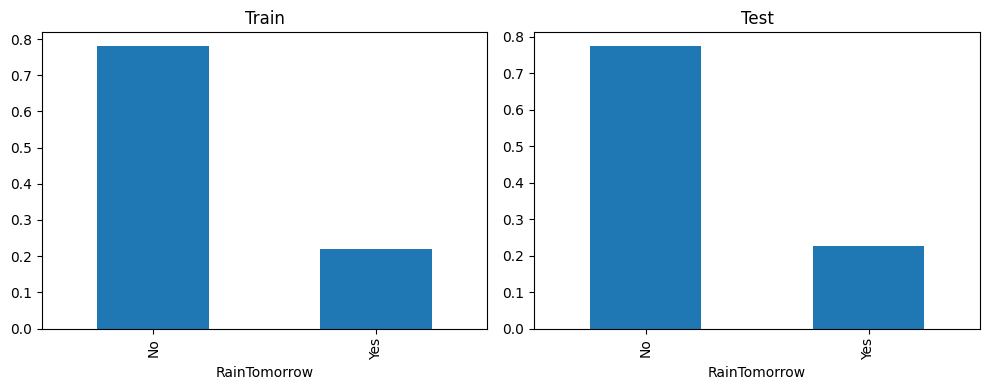

Train


RainTomorrow
No     77.945057
Yes    22.054943
Name: proportion, dtype: float64

Test


RainTomorrow
No     77.29391
Yes    22.70609
Name: proportion, dtype: float64

In [29]:
fig, ax = plt.subplots(1, 2, figsize=(10,4))

train["RainTomorrow"].value_counts(normalize=True).plot.bar(ax=ax[0])
ax[0].set_title("Train")
test["RainTomorrow"].value_counts(normalize=True).plot.bar(ax=ax[1])
ax[1].set_title("Test")

plt.tight_layout()
plt.show()

print("Train")
display(train["RainTomorrow"].value_counts(normalize=True)*100)

print("Test")
display(test["RainTomorrow"].value_counts(normalize=True)*100)

La variable objetivo presenta un desbalance moderado, con aproximadamente un 78% de días sin lluvia y un 22% de días con lluvia. Además, se observa que esta proporción se mantiene prácticamente igual entre los conjuntos de entrenamiento y prueba, lo que indica que el corte temporal no introdujo un desbalance adicional entre ambos períodos.

### Visualizacion sobre train

#### Histograma de numericas 

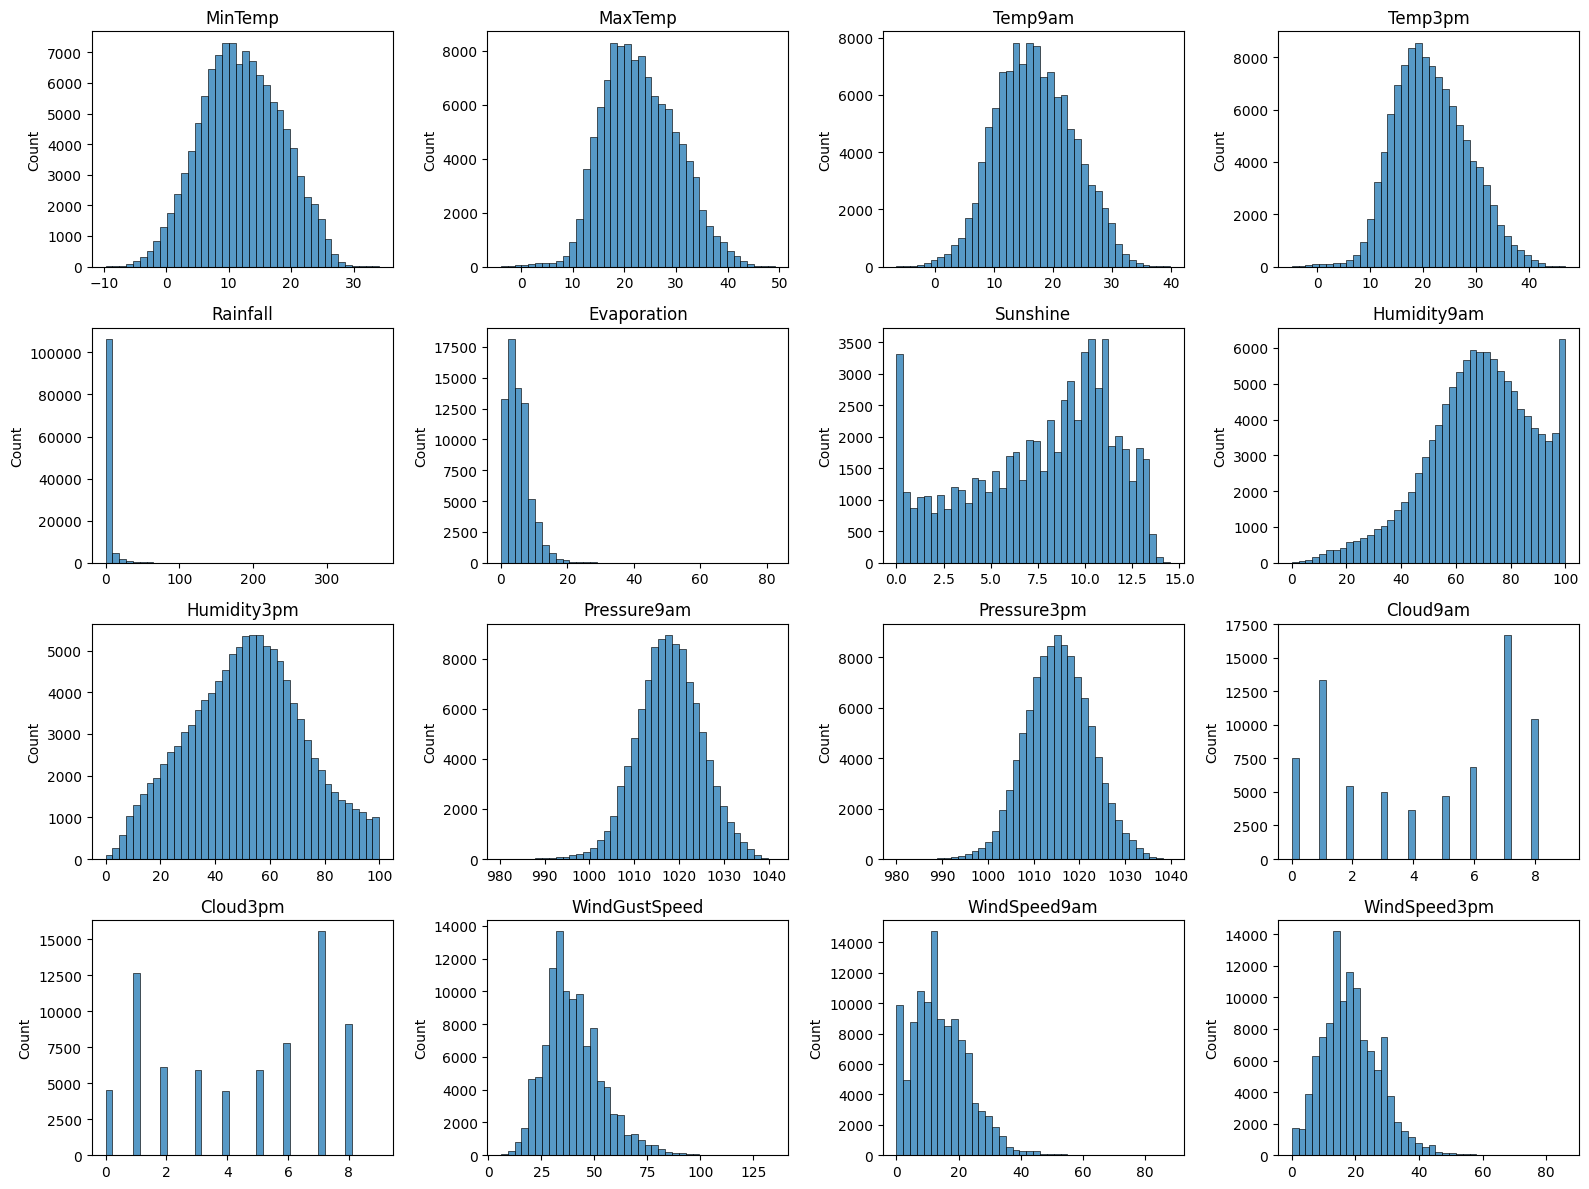

In [30]:
num_cols = ["MinTemp", "MaxTemp", "Temp9am", "Temp3pm",
            "Rainfall", "Evaporation", "Sunshine",
            "Humidity9am", "Humidity3pm",
            "Pressure9am", "Pressure3pm",
            "Cloud9am", "Cloud3pm",
            "WindGustSpeed", "WindSpeed9am", "WindSpeed3pm"]

fig, axes = plt.subplots(4, 4, figsize=(16, 12))

for ax, col in zip(axes.flat, num_cols):
    sns.histplot(train[col], bins=40, ax=ax)
    ax.set_title(col)
    ax.set_xlabel("")

plt.tight_layout()
plt.show()

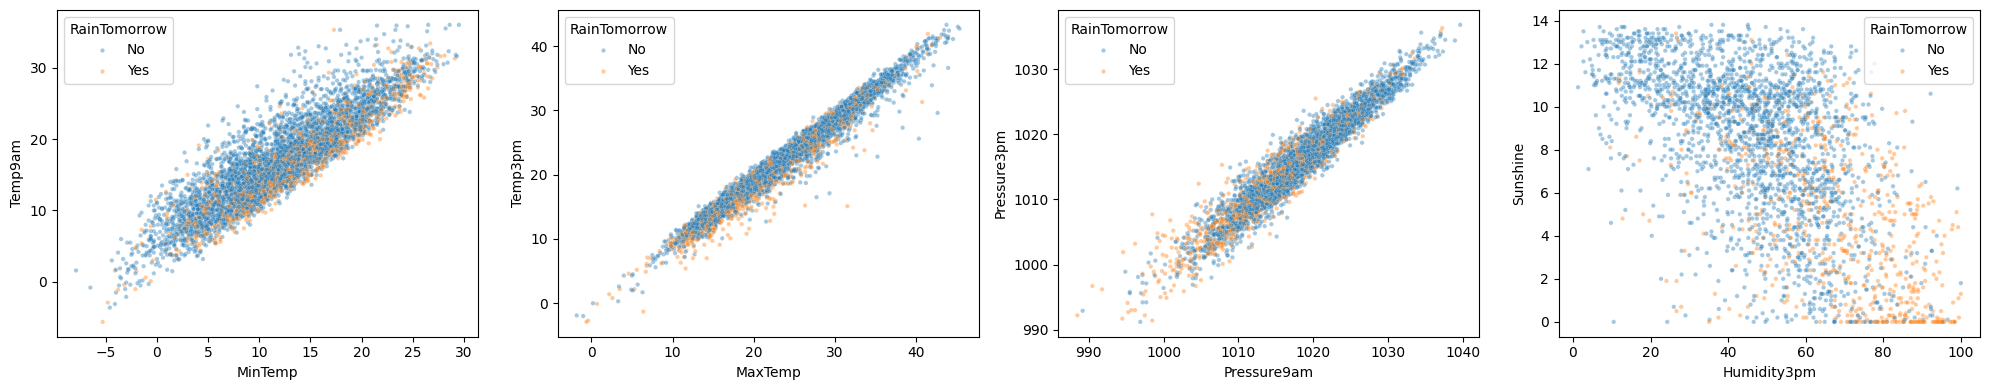

In [31]:
muestra = train.sample(5000, random_state=42)

pares = [("MinTemp", "Temp9am"),
         ("MaxTemp", "Temp3pm"),
         ("Pressure9am", "Pressure3pm"),
         ("Humidity3pm", "Sunshine")]

fig, axes = plt.subplots(1, 4, figsize=(20, 4))

for ax, (x, y) in zip(axes, pares):
    sns.scatterplot(data=muestra, x=x, y=y, hue="RainTomorrow", alpha=0.4, s=10, ax=ax)

plt.tight_layout()
plt.show()

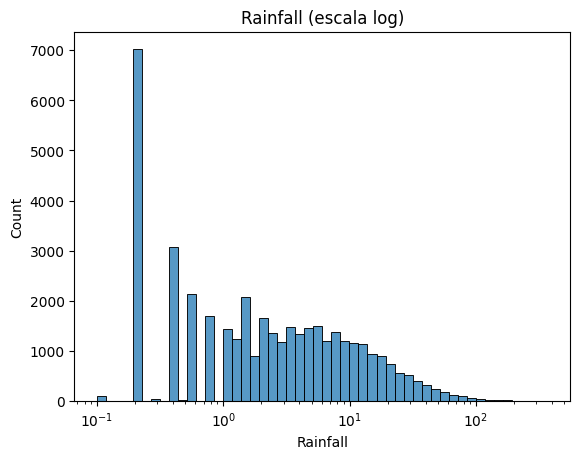

In [32]:
sns.histplot(train.loc[train["Rainfall"] > 0, "Rainfall"], bins=50, log_scale=True)
plt.title("Rainfall (escala log)")
plt.show()

### Correlación entre variables numéricas

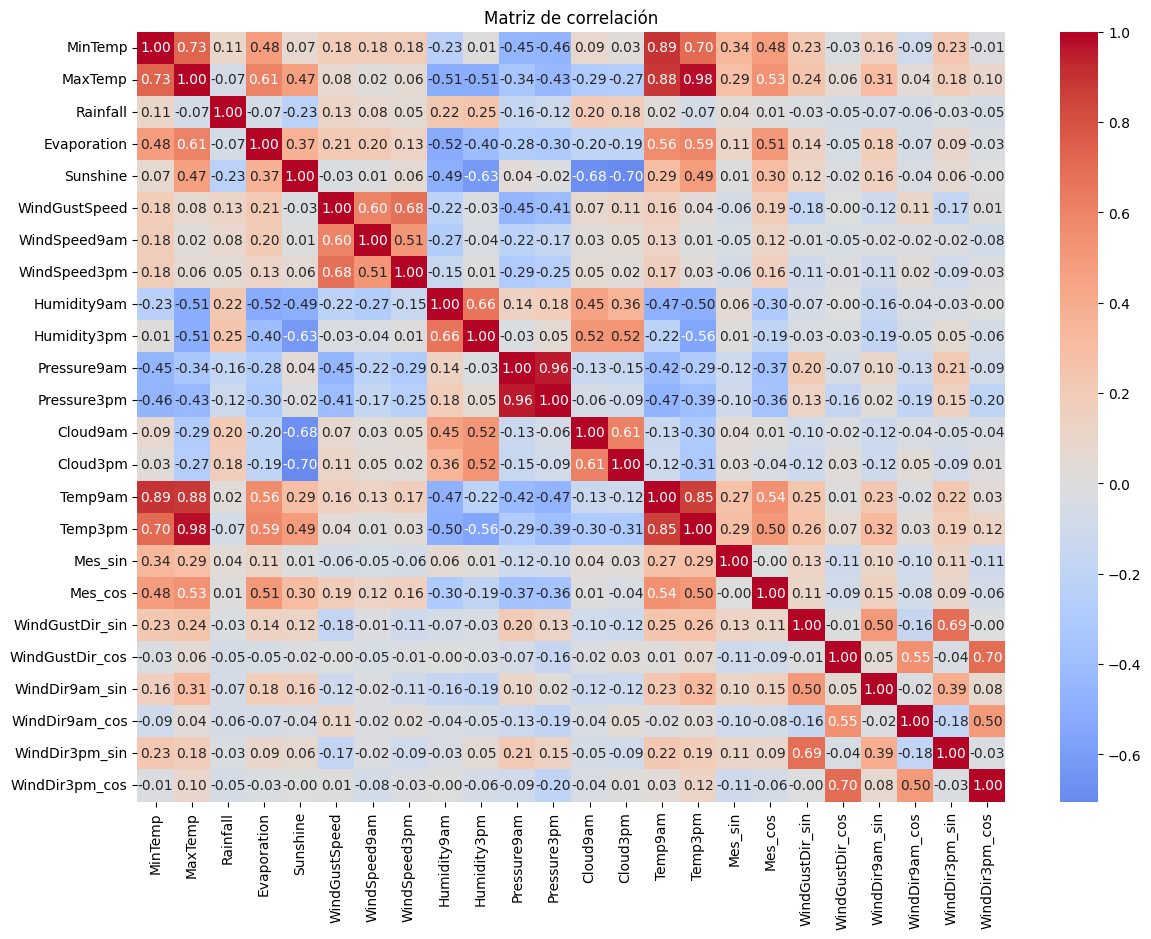

In [48]:
plt.figure(figsize=(14,10))

corr = train.select_dtypes(include="number").corr()

sns.heatmap(corr,cmap="coolwarm",center=0, annot=True, fmt=".2f")
plt.title("Matriz de correlación")
plt.show()

La matriz de correlación permite identificar relaciones lineales entre las variables numéricas del conjunto de datos. Se observan correlaciones elevadas entre variables que describen un mismo fenómeno meteorológico, como MinTemp–Temp9am, MaxTemp–Temp3pm, Pressure9am–Pressure3pm, Humidity9am–Humidity3pm y Cloud9am–Cloud3pm, lo cual era esperable debido a que representan mediciones relacionadas en distintos momentos del día.

También vemos una relacion negativa entre la presión atmosférica y variables asociadas a nubosidad y humedad, tiene sentido con el comportamiento meteorológico esperado. No se detectan correlaciones prácticamente perfectas entre variables distintas, por lo que en esta etapa no se considera necesario eliminar predictores por redundancia.

### Imputación 

In [34]:
from sklearn.impute import KNNImputer
from sklearn.preprocessing import StandardScaler

#### Boxplots para identificar valores atipicos

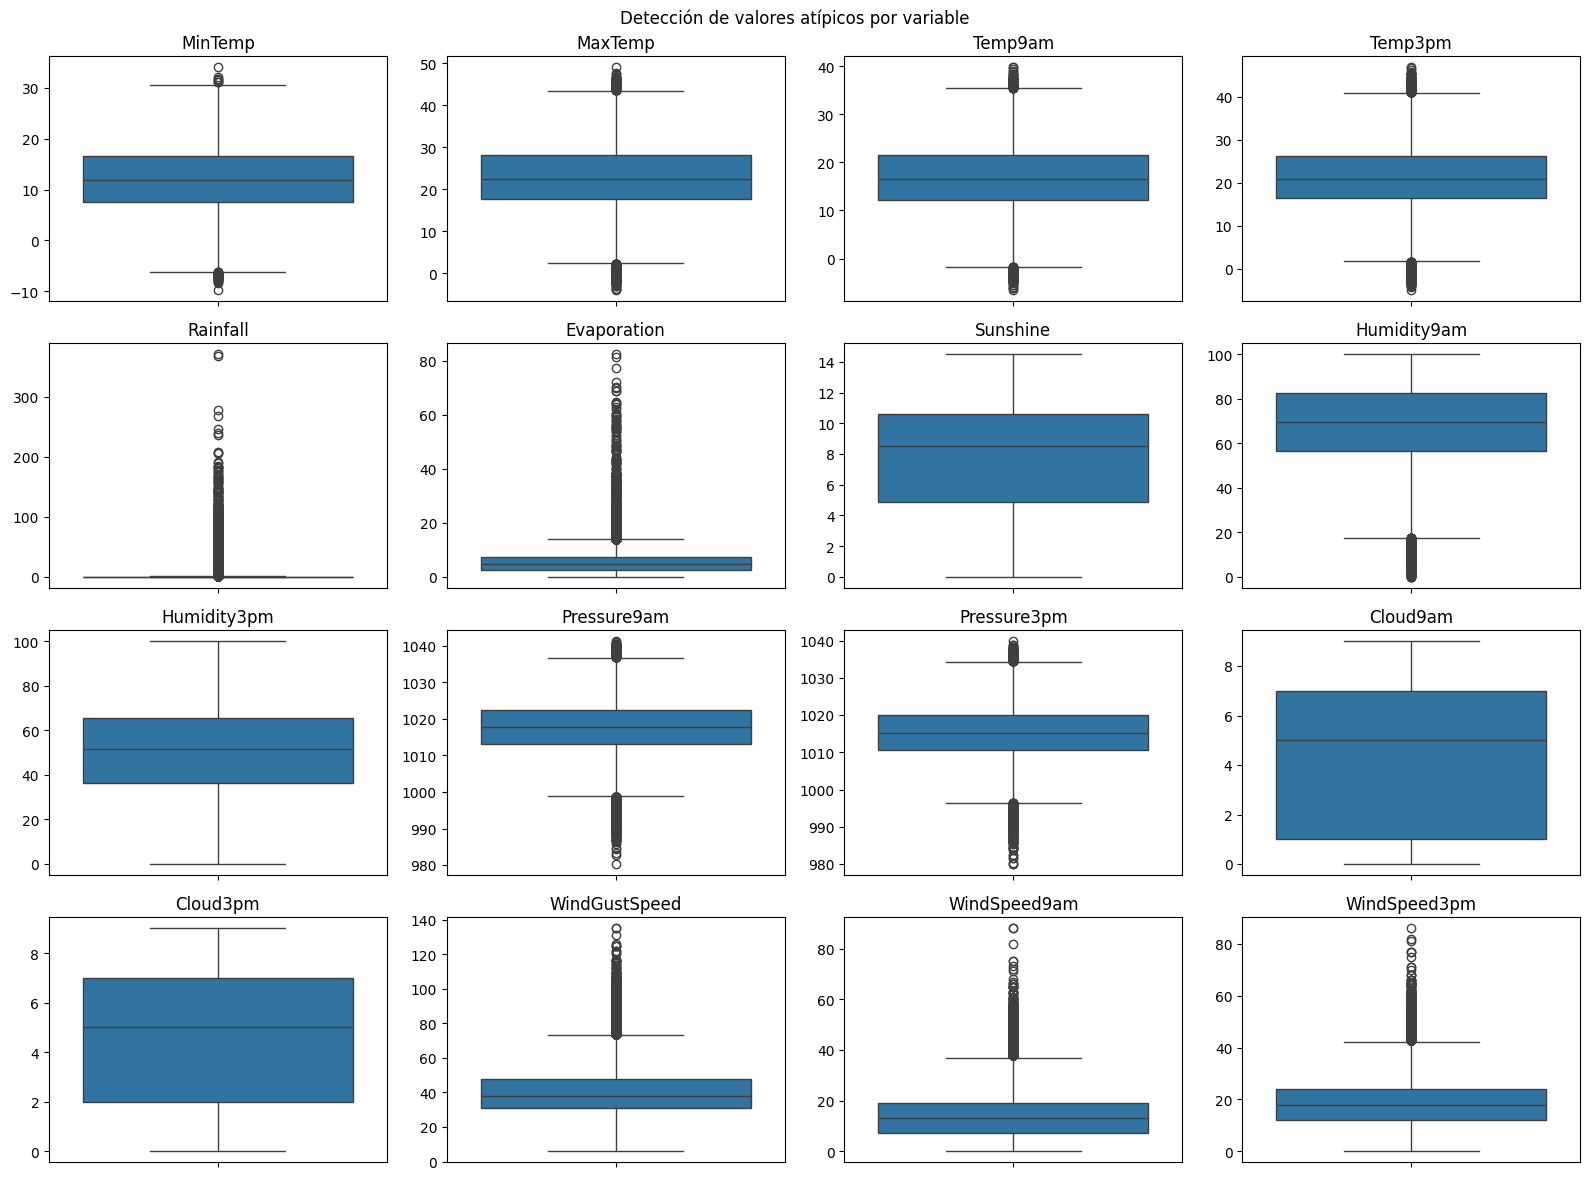

In [35]:
fig, axes = plt.subplots(4, 4, figsize=(16, 12))

for ax, col in zip(axes.flat, num_cols):
    sns.boxplot(y=train[col], ax=ax)
    ax.set_title(col)
    ax.set_ylabel('')

fig.suptitle('Detección de valores atípicos por variable')
plt.tight_layout()
plt.show()

#### Analisis de asimetria con el coeficiente de Fisher

In [36]:
skewness = train.select_dtypes(include="number").skew().sort_values(key=abs, ascending=False)
display(skewness.to_frame("Skew"))

,Skew
Rainfall,10.131885
Evaporation,3.280447
WindGustSpeed,0.861652
WindSpeed9am,0.765662
WindSpeed3pm,0.603638
Sunshine,-0.502650
Humidity9am,-0.488388
Temp3pm,0.256895
MaxTemp,0.237149
Cloud3pm,-0.202303


Basandonos en la informacion brindada por los boxplots y los coeficientes de asimetria, observamos que las variables Rainfall y Evaporation presentan una fuerte asimetría positiva respecto del resto de las variables numéricas. Como el algoritmo KNN utiliza distancias para determinar los vecinos más cercanos, estos valores pueden generar una influencia desproporcionada. Para reducir este efecto vamos a aplicar una transformación logarítmica mediante log1p exclusivamente sobre estas variables antes de la imputación.

Esta transformación se utiliza únicamente durante el proceso de imputación. Una vez finalizado el KNN y luego de rever la estandarización, los valores serán devueltos a su escala original mediante la función expm1, para preservar el valor fisica de estas variables.

In [37]:
train_knn = train.copy()
test_knn = test.copy()

columnas_log = ["Rainfall", "Evaporation"]

train_knn[columnas_log] = np.log1p(train_knn[columnas_log])
test_knn[columnas_log] = np.log1p(test_knn[columnas_log])

#### Imputación de variables numéricas mediante KNN por estado

Las variables numéricas van a ser imputadas mediante el algoritmo KNN, que estima los valores faltantes a partir de las observaciones más similares según una medida de distancia. Para mantener las caracteristicas regionales que mencionamos anteriormente en el trabajo, vamos a realizar la imputacion de fiorma independiente para cada estado australiano, evitando que observaciones geográficamente distantes sean consideradas vecinas.

El algoritmo se ajusta exclusivamente sobre el conjunto de entrenamiento y posteriormente se aplica al conjunto de prueba, evitando así la incorporación de información futura (fuga). Las variables numéricas son estandarizadas mediante StandardScaler, una vez finalizada la imputación, se recupera la escala original de todas las variables.

In [38]:
columnas_knn = [
    "MinTemp",
    "MaxTemp",
    "Rainfall",
    "Evaporation",
    "Sunshine",
    "WindGustSpeed",
    "WindSpeed9am",
    "WindSpeed3pm",
    "Humidity9am",
    "Humidity3pm",
    "Pressure9am",
    "Pressure3pm",
    "Cloud9am",
    "Cloud3pm",
    "Temp9am",
    "Temp3pm",
    "Mes_sin",
    "Mes_cos",
    "WindGustDir_sin",
    "WindGustDir_cos",
    "WindDir9am_sin",
    "WindDir9am_cos",
    "WindDir3pm_sin",
    "WindDir3pm_cos",
]

In [39]:
K = 5

# Un imputer y un scaler por estado, guardados para reutilizarlos más adelante
imputers = {}
scalers = {}

for state in train_knn["State"].unique():

    train_mask = train_knn["State"] == state
    test_mask = test_knn["State"] == state

    train_state = train_knn.loc[train_mask, columnas_knn]
    test_state = test_knn.loc[test_mask, columnas_knn]

    scalers[state] = StandardScaler().fit(train_state)
    train_scaled = scalers[state].transform(train_state)
    test_scaled = scalers[state].transform(test_state)

    imputers[state] = KNNImputer(n_neighbors=K, weights="distance").fit(train_scaled)
    train_imputed = imputers[state].transform(train_scaled)
    test_imputed = imputers[state].transform(test_scaled)

    # Revertimos la estandarización
    train_imputed = pd.DataFrame(scalers[state].inverse_transform(train_imputed),
                                 columns=columnas_knn, index=train_state.index)
    test_imputed = pd.DataFrame(scalers[state].inverse_transform(test_imputed),
                                columns=columnas_knn, index=test_state.index)

    # Revertimos la transformación logarítmica
    train_imputed[columnas_log] = np.expm1(train_imputed[columnas_log])
    test_imputed[columnas_log] = np.expm1(test_imputed[columnas_log])

    # Solo se completan los valores que eran nulos; el resto conserva su valor original
    train_knn.loc[train_mask, columnas_knn] = train.loc[train_mask, columnas_knn].fillna(train_imputed)
    test_knn.loc[test_mask, columnas_knn] = test.loc[test_mask, columnas_knn].fillna(test_imputed)

In [40]:
print("Nulos restantes en train:")
display(train_knn[columnas_knn].isna().sum())

print("\nNulos restantes en test:")
display(test_knn[columnas_knn].isna().sum())

Nulos restantes en train:


MinTemp            0
MaxTemp            0
Rainfall           0
Evaporation        0
Sunshine           0
WindGustSpeed      0
WindSpeed9am       0
WindSpeed3pm       0
Humidity9am        0
Humidity3pm        0
Pressure9am        0
Pressure3pm        0
Cloud9am           0
Cloud3pm           0
Temp9am            0
Temp3pm            0
Mes_sin            0
Mes_cos            0
WindGustDir_sin    0
WindGustDir_cos    0
WindDir9am_sin     0
WindDir9am_cos     0
WindDir3pm_sin     0
WindDir3pm_cos     0
dtype: int64


Nulos restantes en test:


MinTemp            0
MaxTemp            0
Rainfall           0
Evaporation        0
Sunshine           0
WindGustSpeed      0
WindSpeed9am       0
WindSpeed3pm       0
Humidity9am        0
Humidity3pm        0
Pressure9am        0
Pressure3pm        0
Cloud9am           0
Cloud3pm           0
Temp9am            0
Temp3pm            0
Mes_sin            0
Mes_cos            0
WindGustDir_sin    0
WindGustDir_cos    0
WindDir9am_sin     0
WindDir9am_cos     0
WindDir3pm_sin     0
WindDir3pm_cos     0
dtype: int64

#### Comparacion de distribuciones antes y despues de la imputacion

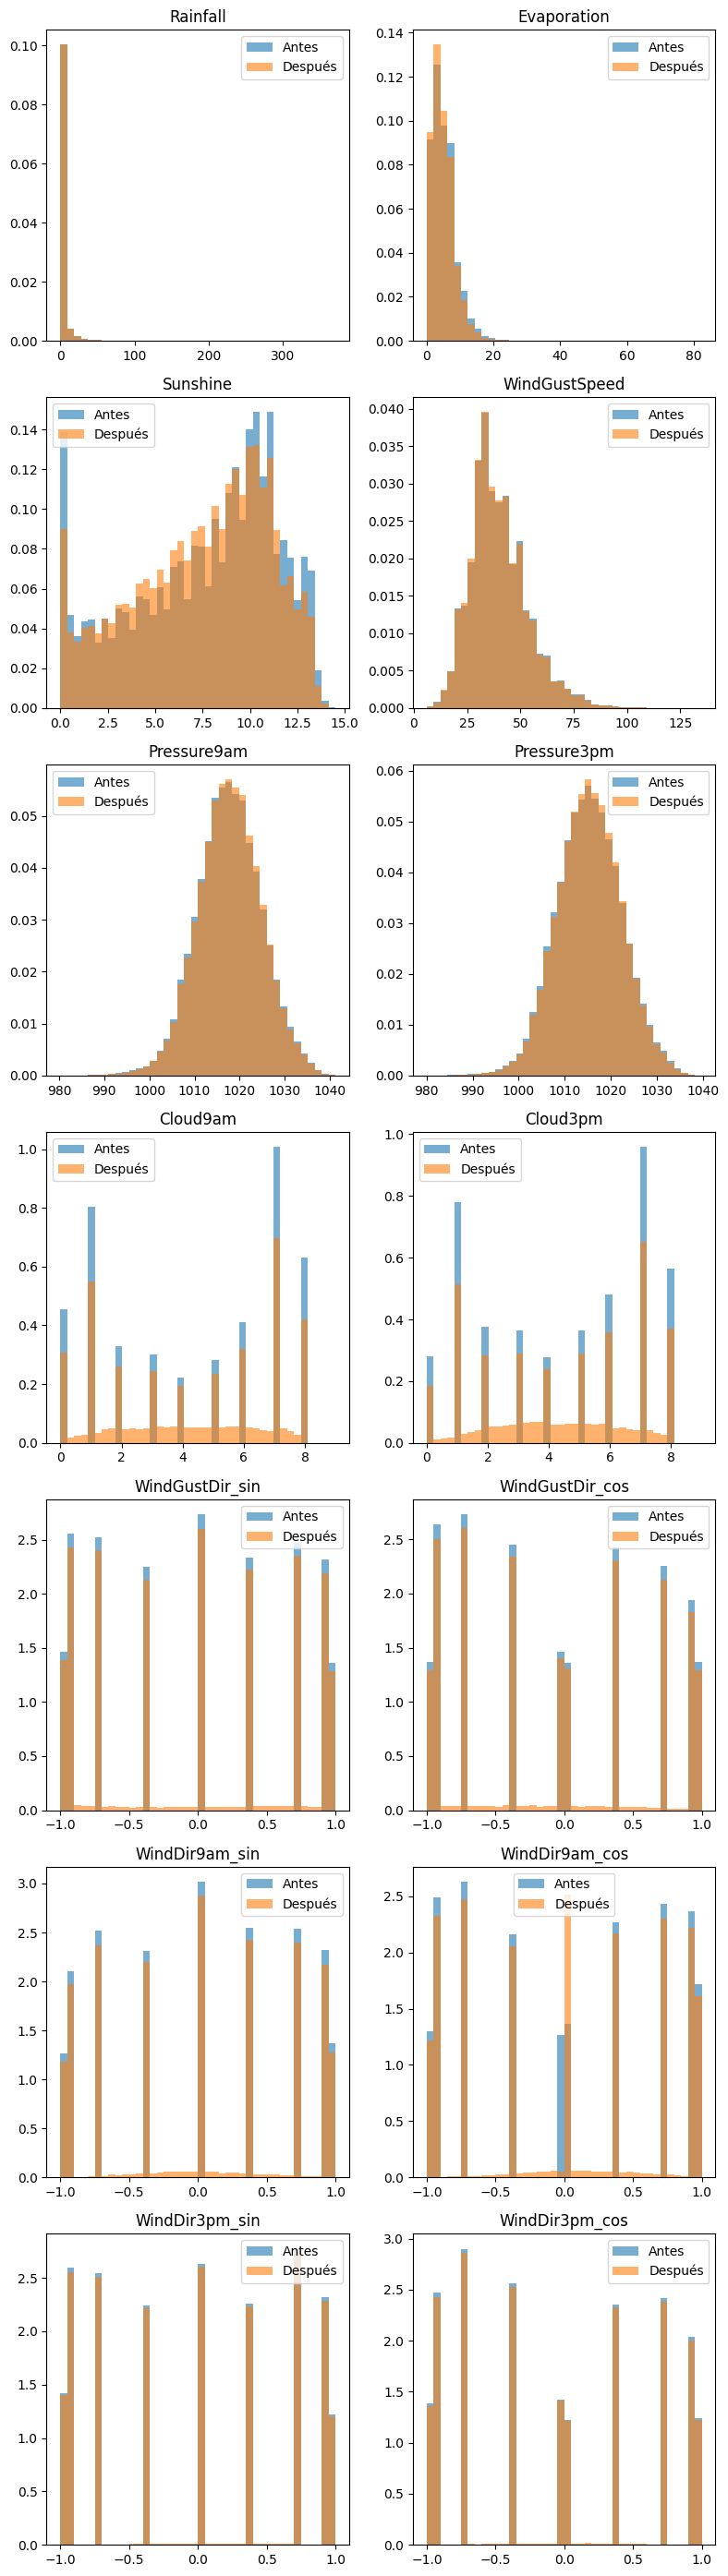

In [41]:
import matplotlib.pyplot as plt

variables_imputadas = [
    "Rainfall",
    "Evaporation",
    "Sunshine",
    "WindGustSpeed",
    "Pressure9am",
    "Pressure3pm",
    "Cloud9am",
    "Cloud3pm",
    "WindGustDir_sin",
    "WindGustDir_cos",
    "WindDir9am_sin",
    "WindDir9am_cos",
    "WindDir3pm_sin",
    "WindDir3pm_cos"
]

ncols = 2
nrows = (len(variables_imputadas) + 1) // ncols

fig, axes = plt.subplots(nrows, ncols, figsize=(8, 4 * nrows))
axes = axes.flatten()

for ax, col in zip(axes, variables_imputadas):
    ax.hist(train[col].dropna(),bins=40,density=True,alpha=0.6,label="Antes")
    ax.hist(train_knn[col],bins=40,density=True,alpha=0.6,label="Después")
    ax.set_title(col)
    ax.legend()

plt.tight_layout()
plt.show()

La comparación de las distribuciones antes y después de la imputación muestra que el procedimiento basado en KNN preserva correctamente el comportamiento estadístico de las variables numéricas. En la mayoría de los casos las distribuciones permanecen practicamente alterarse, observándose únicamente pequeñas diferencias en aquellas variables con una elevada proporción de valores faltantes, como Sunshine. No se detectaron desplazamientos significativos ni la generación de valores fuera de los rangos.

In [42]:
train_knn

,Date,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustSpeed,WindSpeed9am,WindSpeed3pm,...,RainTomorrow,State,Mes_sin,Mes_cos,WindGustDir_sin,WindGustDir_cos,WindDir9am_sin,WindDir9am_cos,WindDir3pm_sin,WindDir3pm_cos
0,2007-11-01,Canberra,7.9,24.3,0.0,3.400000,6.300000,29.0,7.0,20.0,...,Yes,ACT,-5.000000e-01,0.866025,-0.707107,0.707107,-0.707107,-7.071068e-01,-0.707107,7.071068e-01
1,2007-11-02,Canberra,13.3,27.0,3.6,4.400000,9.700000,38.0,5.0,14.0,...,Yes,ACT,-5.000000e-01,0.866025,0.923880,0.382683,1.000000,6.123234e-17,-1.000000,-1.836970e-16
2,2007-11-03,Canberra,13.9,23.1,3.6,5.800000,3.300000,84.0,5.0,6.0,...,Yes,ACT,-5.000000e-01,0.866025,-0.707107,0.707107,0.000000,1.000000e+00,0.382683,9.238795e-01
3,2007-11-04,Canberra,13.0,15.8,39.8,7.200000,9.100000,54.0,30.0,23.0,...,Yes,ACT,-5.000000e-01,0.866025,-0.707107,0.707107,-0.923880,3.826834e-01,-1.000000,-1.836970e-16
4,2007-11-05,Canberra,7.8,16.4,2.8,5.600000,10.600000,49.0,19.0,28.0,...,No,ACT,-5.000000e-01,0.866025,0.382683,-0.923880,0.382683,-9.238795e-01,0.923880,-3.826834e-01
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
114441,2015-12-31,Penrith,15.6,31.0,0.0,6.590691,8.157658,30.0,5.0,9.0,...,No,NSW,-2.449294e-16,1.000000,0.923880,0.382683,-0.382683,9.238795e-01,0.707107,7.071068e-01
114442,2015-12-31,Dartmoor,14.7,40.0,0.0,14.800000,13.600000,56.0,9.0,23.0,...,No,VIC,-2.449294e-16,1.000000,-0.382683,-0.923880,0.000000,1.000000e+00,-0.382683,-9.238795e-01
114443,2015-12-31,MountGinini,13.4,25.0,0.0,6.543265,12.516240,30.0,3.0,6.0,...,No,ACT,-2.449294e-16,1.000000,-0.707107,0.707107,-0.707107,7.071068e-01,-0.382683,9.238795e-01
114444,2015-12-31,MelbourneAirport,22.7,39.7,0.0,15.200000,11.400000,50.0,31.0,20.0,...,No,VIC,-2.449294e-16,1.000000,-0.382683,0.923880,0.000000,1.000000e+00,0.000000,1.000000e+00


In [43]:
# Eliminación de columnas auxiliares
train_knn = train_knn.drop(columns=["State", "Date"])
test_knn = test_knn.drop(columns=["State", "Date"])

### One Hot Encoding

In [44]:
for d in (train_knn, test_knn):
    d["RainToday"] = d["RainToday"].map({"Yes": 1, "No": 0})
    d["RainTomorrow"] = d["RainTomorrow"].map({"Yes": 1, "No": 0})

In [45]:
train_knn = pd.get_dummies(train_knn, columns=["Location"], dtype=int)
test_knn = pd.get_dummies(test_knn, columns=["Location"], dtype=int)
test_knn = test_knn.reindex(columns=train_knn.columns, fill_value=0)

In [46]:
train_knn.head()

,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustSpeed,WindSpeed9am,WindSpeed3pm,Humidity9am,Humidity3pm,...,Location_Townsville,Location_Tuggeranong,Location_Uluru,Location_WaggaWagga,Location_Walpole,Location_Watsonia,Location_Williamtown,Location_Witchcliffe,Location_Wollongong,Location_Woomera
0,7.9,24.3,0.0,3.4,6.3,29.0,7.0,20.0,63.9,28.1,...,0,0,0,0,0,0,0,0,0,0
1,13.3,27.0,3.6,4.4,9.7,38.0,5.0,14.0,79.4,35.8,...,0,0,0,0,0,0,0,0,0,0
2,13.9,23.1,3.6,5.8,3.3,84.0,5.0,6.0,80.9,68.8,...,0,0,0,0,0,0,0,0,0,0
3,13.0,15.8,39.8,7.2,9.1,54.0,30.0,23.0,62.7,55.9,...,0,0,0,0,0,0,0,0,0,0
4,7.8,16.4,2.8,5.6,10.6,49.0,19.0,28.0,67.5,50.1,...,0,0,0,0,0,0,0,0,0,0


### Escalado y separación X/y

In [47]:
X_train = train_knn.drop(columns="RainTomorrow")
y_train = train_knn["RainTomorrow"]
X_test = test_knn.drop(columns="RainTomorrow")
y_test = test_knn["RainTomorrow"]

# Estandarización de las variables continuas
scaler_final = StandardScaler().fit(X_train[num_cols])
X_train[num_cols] = scaler_final.transform(X_train[num_cols])
X_test[num_cols] = scaler_final.transform(X_test[num_cols])